In [1]:
# Read in volume.csv and get avd length, avg width, and avg volume for each species
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


<Figure size 640x480 with 0 Axes>

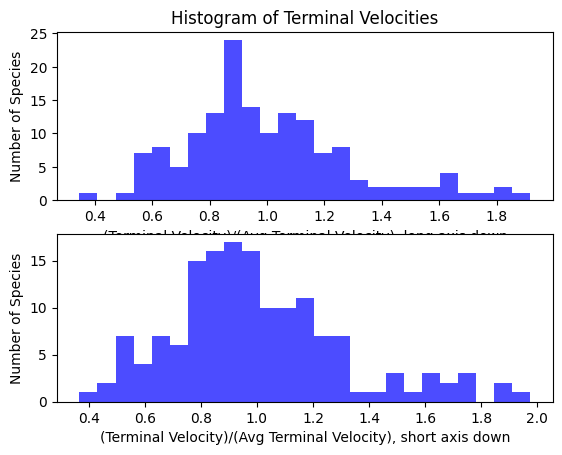

In [2]:


# This is just reading data into an array
def Get_Data(file_path):
    # Read the CSV file into a DataFrame
    df = pd.read_csv(file_path)
    # Get number of rows and columns
    rows, cols = df.shape
    Data = np.zeros((rows, 3))
    # iterate over each row
    
    for index, row in df.iterrows():
        Data[index][0] = row['avg_length']
        Data[index][1] = row['avg_width']
        Data[index][2] = row['avg_volume_estimated']

    return Data

# Calculate terminal velocity coefficients, which is all we need to compare species
def Caclculate_Terminal_Velocity(length, width, volume):

    # Stokes Flow terminal velocity for prolate spherical shapes in air
    a = length
    c = width
    v = volume

    if a == c:
        return v/a, v/a  # Sphere case

    e = np.sqrt(a**2 - c**2)/a # Eccentricity
    L = np.log((1+e)/(1-e))
    Xa = (8/3) * e**3 *(-2*e + (1 + e**2)*L)**(-1) # Drag coefficient factor for long axis down
    Ya = (16/3) * e**3 *(2*e + (3*e**2 -1)*L)**(-1) # Drag coefficient factor for short axis down
    
    # First is falling with long axis down, second is falling with short axis down
    return v/(a*Xa), v/(a*Ya)


# Read data, go through each species, calculate terminal velocities
Data = Get_Data('../../Results/Volume/Volume.csv')
Terminal_Velocities = np.zeros((len(Data),2))
for i in range(len(Data)):
    length = Data[i][0]
    width = Data[i][1]
    volume = Data[i][2]

    Terminal_Velocities[i] = Caclculate_Terminal_Velocity(length, width, volume)

# Get averages
avg_terminal_velocity_long_axis = np.mean(Terminal_Velocities[:,0])
avg_terminal_velocity_short_axis = np.mean(Terminal_Velocities[:,1])


# Divide all by the average
Terminal_Velocities[:,0] /= avg_terminal_velocity_long_axis
Terminal_Velocities[:,1] /= avg_terminal_velocity_short_axis

plt.figure()
fig, (ax1, ax2) = plt.subplots(2, 1)
# histogram of terminal velocities
ax1.hist(Terminal_Velocities[:,0], bins=25, color='blue', alpha=0.7)
ax1.set_xlabel('(Terminal Velocity)/(Avg Terminal Velocity), long axis down')
ax1.set_ylabel('Number of Species')
ax1.set_title('Histogram of Terminal Velocities')

# histogram of terminal velocities
ax2.hist(Terminal_Velocities[:,1], bins=25, color='blue', alpha=0.7)
ax2.set_xlabel('(Terminal Velocity)/(Avg Terminal Velocity), short axis down')
ax2.set_ylabel('Number of Species')
plt.show()

In [3]:
plt.savefig('Terminal_Velocities_Histograms.png')

<Figure size 640x480 with 0 Axes>